In [1]:
import pandas as pd
import warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split,cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

In [2]:
df=pd.read_csv("data/titanic_clean.csv")
df.head(3)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked,HasCabin
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,S,0
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C,1
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,S,0


In [3]:
df["Sex_num"]=df["Sex"].map({"male":0,"female":1})

df=pd.concat([df,pd.get_dummies(df["Embarked"],prefix="Emb")],axis=1)

df["Title"]=df["Name"].str.extract(r",\s*([^.]+)\.")
rare=["Dr","Rev","Major","Col","Mlle","the Countess","Capt",
        "Ms","Sir","Lady","Mme","Don","Jonkheer"]
df["Title"]=df["Title"].replace(rare,"Rare")
df=pd.concat([df,pd.get_dummies(df["Title"],prefix="Title")],axis=1)

df["FamilySize"]=df["SibSp"]+df["Parch"]+1

cols=(["Pclass","Sex_num","Age","SibSp","Parch","Fare","HasCabin",
         "Emb_C","Emb_Q","Emb_S","FamilySize"]
        + [c for c in df.columns if c.startswith("Title_")])

X,y=df[cols],df["Survived"]
print("特征数：",len(cols),"样本数:",len(X))

特征数： 16 样本数: 889


In [4]:
X_train,X_test,y_train,y_test=train_test_split(
    X,y,test_size=0.2,random_state=42
)
scaler=StandardScaler()
X_train_s=scaler.fit_transform(X_train)
X_test_s=scaler.transform(X_test)

In [5]:
##实验A 模型对比
models={
    "逻辑回归":LogisticRegression(max_iter=1000),##给每个特征打分，加权求和，过阈值
    "决策树":DecisionTreeClassifier(random_state=42),##一串if-else问题
    "随机森林":RandomForestClassifier(n_estimators=100,random_state=42),##100课数投票，进行样本随机和特征随机
}

for name,m in models.items():
    m.fit(X_train_s,y_train)
    acc=accuracy_score(y_test,m.predict(X_test_s))
    cv=cross_val_score(m,X,y,cv=5).mean()
    print(f"{name:<8} 测试:{acc:.4f}   CV:{cv:.4f}")##测试测试集准确率  cv交叉验证

逻辑回归     测试:0.8315   CV:0.8257
决策树      测试:0.7809   CV:0.7851


随机森林     测试:0.7584   CV:0.8133


📌 记住这个分工
什么时候	        看哪个	为什么
选模型 / 调参数	CV	    更稳、更公平、不受一次划分的运气影响
最终报告成绩	    测试集	它完全没参与过任何决策，最"干净"

In [6]:
##决策树深度
for d in [None,10,5,4,3,2]:
    m=DecisionTreeClassifier(max_depth=d,random_state=42)
    m.fit(X_train,y_train)

    tr=accuracy_score(y_train,m.predict(X_train))
    te=accuracy_score(y_test,m.predict(X_test))

    m2=DecisionTreeClassifier(max_depth=d,random_state=42)
    cv=cross_val_score(m2,X,y,cv=5).mean()

    print(f"depth={str(d):<5} 实际={m.get_depth():<2}  训练={tr:.4f}  测试={te:.4f}  CV={cv:.4f}")

depth=None  实际=17  训练=0.9902  测试=0.7809  CV=0.7851
depth=10    实际=10  训练=0.9423  测试=0.7921  CV=0.7975
depth=5     实际=5   训练=0.8720  测试=0.8090  CV=0.8088
depth=4     实际=4   训练=0.8551  测试=0.7921  CV=0.8234
depth=3     实际=3   训练=0.8397  测试=0.7921  CV=0.8167
depth=2     实际=2   训练=0.8242  测试=0.7865  CV=0.7829


max_depth 控制决策树"最多问几个问题"。
太深 → 死记硬背（过拟合）→ 训练集 99%，测试 78%
太浅 → 学得太少（欠拟合）→ 两边都低
最佳 → 训练 86%，测试 82%（CV 最高）
这张表就是在找"最佳深度"的过程。

In [7]:
##随机深林的数数量
for n in [10,50,100,200,500]:
    m=RandomForestClassifier(n_estimators=n,random_state=42,n_jobs=1)
    m.fit(X_train,y_train)
    tr=accuracy_score(y_train,m.predict(X_train))
    te=accuracy_score(y_test,m.predict(X_test))
    print(f"n={n:<4}  训练={tr:.4f}  测试={te:.4f}")

n=10    训练=0.9803  测试=0.8090


n=50    训练=0.9902  测试=0.7640


n=100   训练=0.9902  测试=0.7584


n=200   训练=0.9902  测试=0.7528


n=500   训练=0.9902  测试=0.7640


随机森林 = 让 100 个"看的数据都不一样"的决策树各自判断，然后投票。
为什么有用？因为它们犯的错不一样，投票能互相纠正。
但前提是：每棵树本身不能太差（不能严重过拟合）。

树的数量解决"抖不抖"，不解决"准不准"。
要"准"，靠每棵树学得好（调深度）。
要"稳"，靠多请人投票（加树）。
这两件事要分清。

In [8]:
##随机森林调深度
for d in [3,4,5,7,None]:
    m=RandomForestClassifier(n_estimators=200,max_depth=d,random_state=42,n_jobs=1)
    m.fit(X_train,y_train)
    tr=accuracy_score(y_train,m.predict(X_train))
    te=accuracy_score(y_test,m.predict(X_test))

    m2=RandomForestClassifier(n_estimators=100,max_depth=d,random_state=42,n_jobs=1)
    cv=cross_val_score(m2,X,y,cv=5).mean()

    print(f"depth:{str(d):<5}   训练={tr:.4f}  测试={te:.4f}  CV={cv:.4f}")

depth:3       训练=0.8368  测试=0.8034  CV=0.8144


depth:4       训练=0.8425  测试=0.8146  CV=0.8279


depth:5       训练=0.8551  测试=0.8146  CV=0.8302


depth:7       训练=0.8987  测试=0.7865  CV=0.8223


depth:None    训练=0.9902  测试=0.7528  CV=0.8133


In [9]:
##特征的重要性
rf=RandomForestClassifier(n_estimators=200,max_depth=5,random_state=42)
rf.fit(X_train,y_train)

imp=pd.Series(rf.feature_importances_,index=cols).sort_values(ascending=False)
print(imp.head(10).round(4).to_string())

Title_Mr      0.2360
Sex_num       0.1879
Fare          0.1070
Pclass        0.0955
FamilySize    0.0660
Age           0.0585
Title_Mrs     0.0522
HasCabin      0.0472
Title_Miss    0.0470
SibSp         0.0376


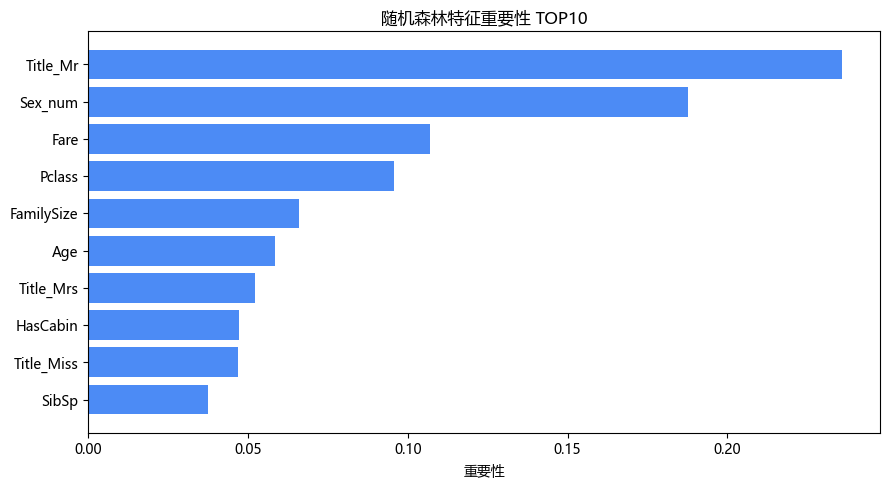

In [10]:
##柱状图
import matplotlib.pyplot as plt
plt.rcParams["font.sans-serif"]=["Microsoft YaHei"]
plt.rcParams["axes.unicode_minus"]=False

top10=imp.head(10).sort_values()

plt.figure(figsize=(9,5))
plt.barh(top10.index,top10.values,color="#4C8BF5")
plt.title("随机森林特征重要性 TOP10")
plt.xlabel("重要性")
plt.tight_layout()
plt.show()

## 结论

### 1. 模型不是越复杂越好
| 模型 | 测试集 | 交叉验证 |
| --- | --- | --- |
| 逻辑回归 | 0.8315 | 0.8257 |
| 决策树（默认） | 0.7809 | 0.7851 |
| 随机森林（默认） | 0.7584 | 0.8133 |

数据量小（889 行）时，简单的逻辑回归反而最稳。

### 2. 过拟合的典型症状
决策树不限制深度：训练集 99.02%，测试集 78.09%。
训练集和测试集差距越大，过拟合越严重。

### 3. 调参的价值
同一棵决策树，max_depth 从 None 到 4，CV 从 0.7851 提升到 0.8234。
随机森林加 max_depth=5 后，测试集从 0.7528 提升到 0.8146。
不改模型、不改数据，只改一个参数，效果就能提升。

### 4. 你造的特征真的有用
随机森林特征重要性 Top 5：
Title_Mr（第1）、Sex_num、Fare、Pclass、FamilySize（第5）

第 5 课造的 Title 和 FamilySize 都进了前五。
